# Customer Segmentation Analysis (RFM + K-Means)
**Oasis Infobyte SIP — Data Analytics L1 Task 2** · Steven Manuel Rios

Dataset: **Online Retail**, UCI ML Repository (id 352): 541,909 transactions from a UK online gift retailer, Dec 2010 – Dec 2011.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
df = pd.read_csv("data/online_retail.csv.gz", dtype={"InvoiceNo": str, "StockCode": str}, parse_dates=["InvoiceDate"])
print(df.shape); print(df.dtypes); df.isnull().sum()

(541909, 8)
InvoiceNo                 str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## 1. Cleaning
* Drop rows with no `CustomerID`, since they cannot be segmented.
* Remove cancellations (InvoiceNo starting with **C**) and non-positive quantities or prices, which are returns and adjustments.
* Drop exact duplicates.

In [3]:
n0 = len(df)
df = df.dropna(subset=["CustomerID"])
df = df[~df["InvoiceNo"].str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].drop_duplicates()
df["CustomerID"] = df["CustomerID"].astype(int).astype(str)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
print(f"Rows: {n0:,} -> {len(df):,}; customers: {df.CustomerID.nunique():,}")

Rows: 541,909 -> 392,692; customers: 4,338


## 2. Descriptive statistics: purchase value, frequency, CLV

In [4]:
inv = df.groupby("InvoiceNo").agg(cust=("CustomerID", "first"), value=("Revenue", "sum"))
cust = inv.groupby("cust").agg(orders=("value", "size"), total=("value", "sum"))
lifespan_days = (df.InvoiceDate.max() - df.InvoiceDate.min()).days
print(f"Average purchase (order) value: £{inv.value.mean():.2f}")
print(f"Average purchase frequency: {cust.orders.mean():.2f} orders per customer over {lifespan_days} days")
print(f"Average customer lifetime value (observed revenue per customer): £{cust.total.mean():.2f} (median £{cust.total.median():.2f})")

Average purchase (order) value: £479.56
Average purchase frequency: 4.27 orders per customer over 373 days
Average customer lifetime value (observed revenue per customer): £2048.69 (median £668.57)


## 3. Feature selection: RFM
* **Recency**: days since the last purchase (lower is better)
* **Frequency**: number of distinct invoices
* **Monetary**: total spend

These three features summarise purchasing behaviour and are standard for retail segmentation. They are log-transformed to reduce the heavy skew, then standardised.

In [5]:
snap = df.InvoiceDate.max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(Recency=("InvoiceDate", lambda s: (snap - s.max()).days), Frequency=("InvoiceNo", "nunique"), Monetary=("Revenue", "sum"))
rfm.describe().round(1)

,Recency,Frequency,Monetary
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2048.7
std,100.0,7.7,8985.2
min,1.0,1.0,3.8
25%,18.0,1.0,306.5
50%,51.0,2.0,668.6
75%,142.0,5.0,1660.6
max,374.0,209.0,280206.0


In [6]:
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(np.log1p(rfm))

## 4. Elbow method

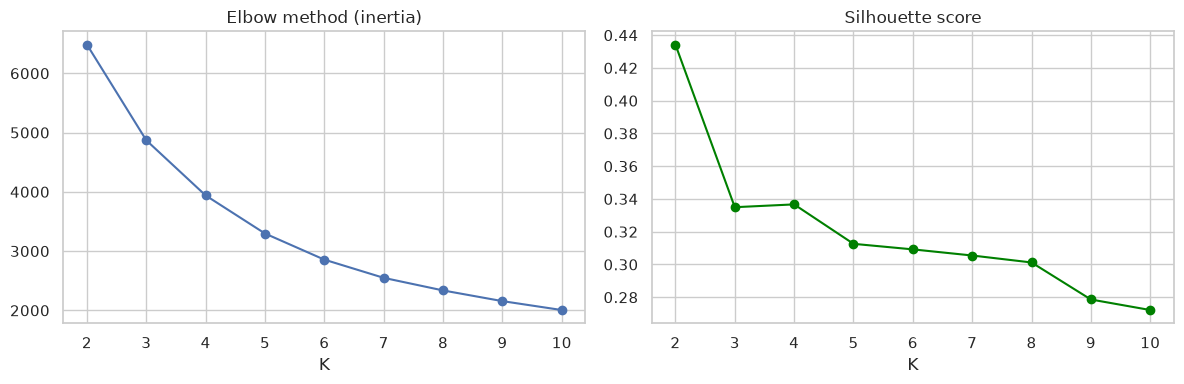

{2: np.float64(0.434), 3: np.float64(0.335), 4: np.float64(0.337), 5: np.float64(0.313), 6: np.float64(0.309), 7: np.float64(0.305), 8: np.float64(0.301), 9: np.float64(0.279), 10: np.float64(0.272)}


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
ks = range(2, 11); inertia = []; sil = []
for k in ks:
    km = KMeans(k, n_init=10, random_state=42).fit(X); inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_, sample_size=3000, random_state=0))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("K")
ax[1].plot(ks, sil, "o-", color="green"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("K")
save("elbow"); print(dict(zip(ks, np.round(sil, 3))))

The inertia curve bends at **K = 4**, where the gains from extra clusters flatten out. K = 2 has a higher silhouette score but is too coarse for marketing use, so **K = 4** is used.

In [8]:
km = KMeans(4, n_init=10, random_state=42).fit(X); rfm["Cluster"] = km.labels_
prof = rfm.groupby("Cluster").agg(Recency=("Recency", "mean"), Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean"), Customers=("Recency", "size")).round(1)
prof.sort_values("Monetary", ascending=False)

,Recency,Frequency,Monetary,Customers
Cluster,,,,
0,12.2,13.8,8088.0,713
3,71.6,4.1,1801.8,1166
2,17.7,2.2,557.3,837
1,181.5,1.3,341.0,1622


## 5. Cluster visualisation

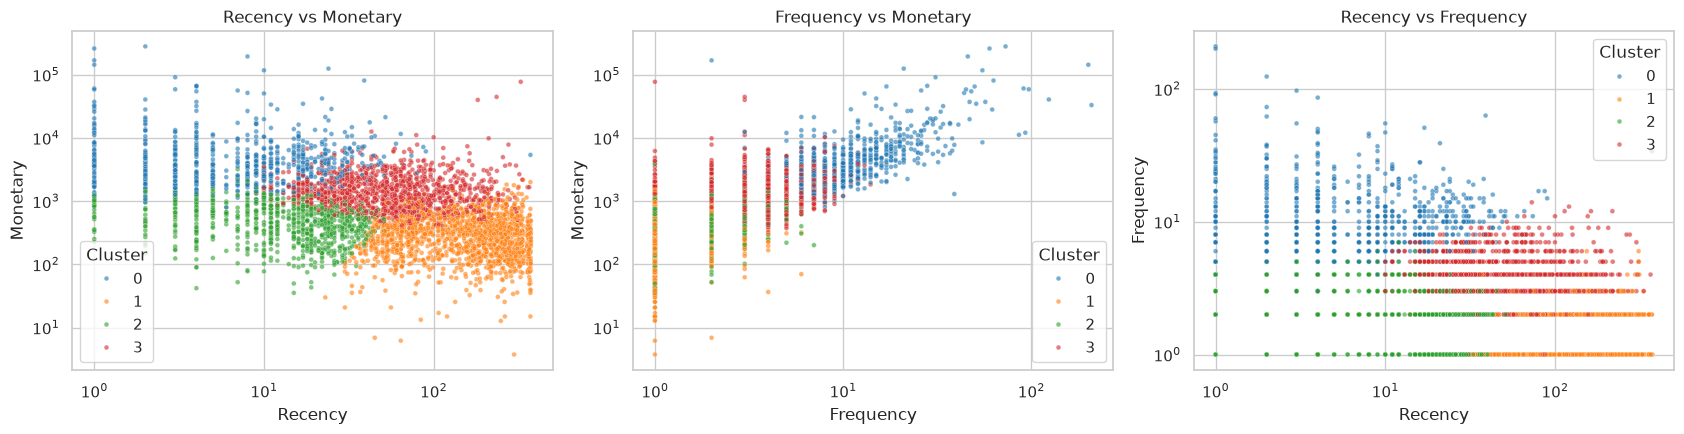

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (x, y) in zip(ax, [("Recency", "Monetary"), ("Frequency", "Monetary"), ("Recency", "Frequency")]):
    sns.scatterplot(data=rfm, x=x, y=y, hue="Cluster", palette="tab10", s=12, ax=a, alpha=.6); a.set_xscale("log"); a.set_yscale("log"); a.set_title(f"{x} vs {y}")
save("clusters")

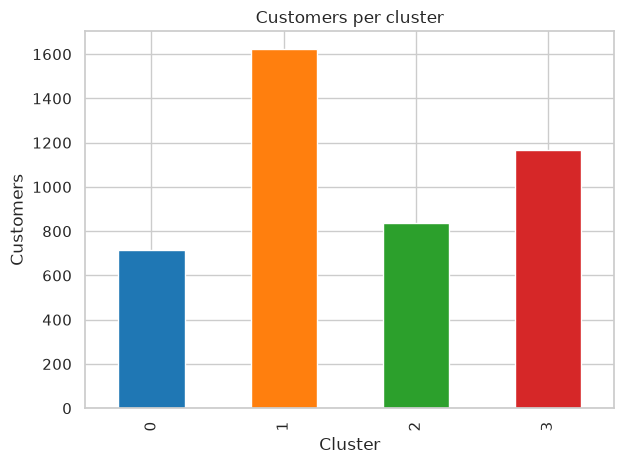

In [10]:
rfm["Cluster"].value_counts().sort_index().plot.bar(color=sns.color_palette("tab10", 4)); plt.title("Customers per cluster"); plt.ylabel("Customers"); save("cluster_sizes")

## Cluster profiles & marketing actions
| Cluster | Profile | Recency (d) | Orders | Spend (£) | Customers | Recommended action |
|---|---|---|---|---|---|---|
| 0 | **Champions** | 12 | 13.8 | 8,088 | 713 | VIP / loyalty tier, early access, referral programme. Do not over-discount. |
| 3 | **Loyal but cooling** | 72 | 4.1 | 1,802 | 1,166 | Personalised "we miss you" offers and cross-sell recommendations to bring them back to Champion frequency. |
| 2 | **New / promising** | 18 | 2.2 | 557 | 837 | Onboarding emails and a second-purchase incentive to build the habit. |
| 1 | **Lost / hibernating** | 182 | 1.3 | 341 | 1,622 | Low-cost win-back campaign with a strong discount, then stop marketing to non-responders. |

**Key insight:** the 713 Champions (16% of customers) account for about 65% of revenue (713 × £8,088 ≈ £5.8M of ≈£8.9M), so retaining them matters most.